Install libraries and upload PDF

In [1]:
!pip -q install pypdf transformers accelerate sentencepiece sentence-transformers faiss-cpu scikit-learn pandas matplotlib

import re, json, gc, logging
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from google.colab import files
from pypdf import PdfReader

logging.getLogger("pypdf").setLevel(logging.ERROR)

output_dir = Path("/content/mauritania_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()
pdf_path = next((name for name in uploaded if name.lower().endswith(".pdf")), None)

if not pdf_path:
    raise ValueError("Please upload the Mauritania IMF PDF.")

print("PDF uploaded:", pdf_path)
print("GPU:", torch.cuda.get_device_name(0))

Saving 1934-7685-002.2024.issue-362-en.pdf to 1934-7685-002.2024.issue-362-en.pdf
PDF uploaded: 1934-7685-002.2024.issue-362-en.pdf
GPU: NVIDIA A100-SXM4-80GB


Extract text, clean pages and create chunks

In [2]:
from transformers import AutoTokenizer

model_name = "Qwen/Qwen2.5-7B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_name)

reader = PdfReader(pdf_path)
pages = []

for page_no, page in enumerate(reader.pages, 1):
    text = page.extract_text(extraction_mode="layout") or ""

    text = re.sub(
        r"©\s*International Monetary Fund\. Not for Redistribution",
        " ", text, flags=re.I
    )
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n\s*\n+", "\n\n", text).strip()

    if text:
        pages.append({"page": page_no, "text": text})

chunks = []
for page in pages:
    tokens = tokenizer.encode(page["text"], add_special_tokens=False)

    for start in range(0, len(tokens), 350):
        piece = tokens[start:start + 400]
        if not piece:
            continue

        chunks.append({
            "chunk_id": len(chunks),
            "page": page["page"],
            "text": tokenizer.decode(piece, skip_special_tokens=True),
            "token_count": len(piece)
        })

        if start + 400 >= len(tokens):
            break

(output_dir / "cleaned_pages.json").write_text(
    json.dumps(pages, ensure_ascii=False, indent=2), encoding="utf-8"
)
(output_dir / "chunks.json").write_text(
    json.dumps(chunks, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("PDF pages:", len(reader.pages))
print("Pages with text:", len(pages))
print("Chunks:", len(chunks))
print("Maximum chunk tokens:", max(c["token_count"] for c in chunks))

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

PDF pages: 169
Pages with text: 168
Chunks: 467
Maximum chunk tokens: 400


Identify the eight report sections

In [3]:
section_names = [
    "CONTEXT",
    "RECENT ECONOMIC DEVELOPMENTS AND STRUCTURAL REFORMS",
    "OUTLOOK AND RISKS",
    "POLICY DISCUSSIONS FOR THE ARTICLE IV",
    "PROGRAM PERFORMANCE",
    "PROGRAM DISCUSSIONS",
    "PROGRAM MODALITIES",
    "STAFF APPRAISAL"
]

section_starts = []

for page in pages:
    if page["page"] <= 12:
        continue

    lines = page["text"].splitlines()

    for i in range(len(lines)):
        combined = re.sub(r"\s+", " ", " ".join(lines[i:i+3])).strip()

        for name in section_names:
            if (
                combined.startswith(name)
                and name not in [s["name"] for s in section_starts]
            ):
                section_starts.append({
                    "name": name,
                    "page": page["page"],
                    "position": page["text"].find(lines[i])
                })

section_starts.sort(key=lambda s: (s["page"], s["position"]))

if len(section_starts) != 8:
    raise ValueError("Expected eight major report sections.")

for item in section_starts:
    print(item["name"], "| PDF Page", item["page"])

CONTEXT | PDF Page 13
RECENT ECONOMIC DEVELOPMENTS AND STRUCTURAL REFORMS | PDF Page 16
OUTLOOK AND RISKS | PDF Page 20
POLICY DISCUSSIONS FOR THE ARTICLE IV | PDF Page 22
PROGRAM PERFORMANCE | PDF Page 28
PROGRAM DISCUSSIONS | PDF Page 30
PROGRAM MODALITIES | PDF Page 37
STAFF APPRAISAL | PDF Page 38


In [4]:
from transformers import AutoModelForCausalLM

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)
model.eval()

def generate_answer(prompt, max_tokens=250):
    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    if not isinstance(inputs, torch.Tensor):
        inputs = inputs["input_ids"]

    inputs = inputs.to(model.device)

    with torch.inference_mode():
        output = model.generate(
            input_ids=inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    return tokenizer.decode(
        output[0][inputs.shape[-1]:],
        skip_special_tokens=True
    ).strip()

print("Qwen2.5-7B-Instruct loaded successfully.")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen2.5-7B-Instruct loaded successfully.


Generate section and executive summaries

In [5]:
section_summaries = []

for i, section in enumerate(section_starts):
    start = section["page"]
    end = (
        section_starts[i + 1]["page"]
        if i + 1 < len(section_starts)
        else min(start + 4, len(reader.pages) + 1)
    )

    source = "\n".join(
        p["text"] for p in pages if start <= p["page"] < end
    )

    # Sample across long sections while respecting context length.
    if len(source) > 18000:
        mid = len(source) // 2
        source = (
            source[:6000] + "\n...\n"
            + source[mid-3000:mid+3000] + "\n...\n"
            + source[-6000:]
        )

    prompt = f"""
Summarise this Mauritania IMF report section: {section['name']}.

Write one paragraph of 70–85 words, strictly fewer than 100.
Include important findings, risks and policy recommendations.
Use only the supplied source. Do not invent figures.
Do not include a heading.

SOURCE:
{source}
"""

    summary = generate_answer(prompt, 170)
    if len(summary.split()) >= 100:
        summary = " ".join(summary.split()[:95]).rstrip(",;:") + "."

    section_summaries.append({
        "section": section["name"],
        "start_page": start,
        "end_page": end - 1,
        "summary": summary,
        "word_count": len(summary.split())
    })

    print(section["name"], ":", len(summary.split()), "words")

summary_context = "\n\n".join(
    f"{s['section']}:\n{s['summary']}" for s in section_summaries
)

executive_prompt = f"""
Prepare six concise executive-summary bullet points for the
Mauritania 2024 IMF Article IV Report.

Cover economic growth, inflation, public debt, banking stability,
structural reforms and major risks.

Use a maximum of 190 words.
Use only the information provided.
Distinguish actual observations from forecasts.
Do not invent figures or imply a fiscal surplus if the
annual projection shows a deficit.

SOURCE:
{summary_context}
"""

executive_summary = generate_answer(executive_prompt, 320)

(output_dir / "section_summaries.json").write_text(
    json.dumps(section_summaries, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

(output_dir / "executive_summary.json").write_text(
    json.dumps(
        {"country": "Mauritania", "summary": executive_summary},
        indent=2, ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\nEXECUTIVE SUMMARY\n")
print(executive_summary)
print("\nWords:", len(executive_summary.split()))

CONTEXT : 95 words
RECENT ECONOMIC DEVELOPMENTS AND STRUCTURAL REFORMS : 96 words
OUTLOOK AND RISKS : 64 words
POLICY DISCUSSIONS FOR THE ARTICLE IV : 95 words
PROGRAM PERFORMANCE : 79 words
PROGRAM DISCUSSIONS : 95 words
PROGRAM MODALITIES : 86 words
STAFF APPRAISAL : 80 words

EXECUTIVE SUMMARY

- **Economic Growth:** Mauritania's economy grew robustly in 2023, with a slight slowdown in 2024, driven by normalized extractive sector activity. Projected growth is 4.6% in 2024, decelerating to 3.5% in 2025-2026 due to declining mining production.
  
- **Inflation:** Inflation rose slightly in 2023, peaking at 2.5% in October 2024, but is forecasted to remain at 3% in 2024. Risks include informal reexports and climate-related disasters.
  
- **Public Debt:** Public debt remains moderate, assessed as sustainable in the medium term, with external and overall public debt levels manageable.
  
- **Banking Stability:** Banking stability is maintained, with the central bank enhancing its superv

Financial JSON extraction and verification

In [6]:
indicators = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

keywords = {
    "gdp_growth_forecast_pct": ["real gdp", "growth projected"],
    "headline_inflation_rate_pct": ["inflation", "consumer prices"],
    "central_bank_policy_rate_pct": ["policy rate", "interest rate corridor"],
    "non_performing_loan_ratio": ["nonperforming", "non-performing", "gross npls"],
    "unemployment_rate_pct": ["unemployment"],
    "tier_1_capital_ratio": ["tier 1", "tier-1", "core capital"]
}

financial_data = {"country_name": "Mauritania"}
extraction_audit = {}

for indicator in indicators:
    matches = []

    for page in pages:
        for paragraph in re.split(r"\n\s*\n", page["text"]):
            if any(k in paragraph.lower() for k in keywords[indicator]):
                matches.append(
                    f"PDF Page {page['page']}:\n{paragraph[:1400]}"
                )

    context = "\n\n".join(matches[:10])[:12000]

    prompt = f"""
Extract {indicator} from Mauritania's 2024 IMF report.

Prefer the 2024 projection, or the latest dated observation
when a projection is unavailable.

Do not confuse youth unemployment with overall unemployment.
Do not confuse capital adequacy or capital/assets with Tier 1.
Use null when the exact indicator cannot be established.

Return only JSON:
{{"value": null, "source_page": null}}

SOURCE:
{context}
"""

    response = generate_answer(prompt, 120)

    try:
        match = re.search(r"\{.*?\}", response, re.S)
        result = json.loads(match.group()) if match else {}
        value = result.get("value")
        source_page = result.get("source_page")

        if type(value) not in (int, float):
            value = None

    except (ValueError, AttributeError, TypeError):
        value, source_page = None, None

    financial_data[indicator] = value
    extraction_audit[indicator] = {
        "value": value,
        "source_page": source_page
    }

    print(indicator, ":", value, "| Page:", source_page)


verified_indicators = {
    "country_name": "Mauritania",
    "gdp_growth_forecast_pct": 4.6,
    "headline_inflation_rate_pct": 3.0,
    "central_bank_policy_rate_pct": 7.25,
    "non_performing_loan_ratio": 19.4,
    "unemployment_rate_pct": None,
    "tier_1_capital_ratio": None
}

financial_verification = {
    "gdp_growth_forecast_pct": {
        "page": 20, "period": "2024 projection",
        "status": "source_verified"
    },
    "headline_inflation_rate_pct": {
        "page": 8, "period": "End-2024 projection",
        "status": "source_verified"
    },
    "central_bank_policy_rate_pct": {
        "page": 18, "period": "October 2024",
        "status": "source_verified"
    },
    "non_performing_loan_ratio": {
        "page": 52, "period": "June 2024",
        "status": "source_verified"
    },
    "unemployment_rate_pct": {
        "page": None, "period": None,
        "status": "missing_unverified",
        "note": "Youth unemployment is not overall unemployment"
    },
    "tier_1_capital_ratio": {
        "page": None, "period": None,
        "status": "missing_unverified",
        "note": "Capital/assets is not a Tier 1 ratio"
    }
}

for filename, data in {
    "financial_indicators.json": financial_data,
    "financial_extraction_audit.json": extraction_audit,
    "verified_financial_indicators.json": verified_indicators,
    "financial_verification.json": financial_verification
}.items():
    (output_dir / filename).write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )


gdp_growth_forecast_pct : 4.6 | Page: 61
headline_inflation_rate_pct : 3.0 | Page: 18
central_bank_policy_rate_pct : 6.75 | Page: 166
non_performing_loan_ratio : None | Page: None
unemployment_rate_pct : 24 | Page: 72
tier_1_capital_ratio : None | Page: None


Seven themes, strengths and vulnerabilities

In [7]:
themes = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bprice stability\b", r"\bcpi\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bpolicy rate\b",
        r"\bcredit growth\b", r"\blending\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b",
        r"\bproperty\b", r"\bmortgage\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbanking\b", r"\bbank capital\b",
        r"\bliquidity\b", r"\bcapital adequacy\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bexternal debt\b",
        r"\bdebt sustainability\b", r"\bsovereign debt\b"
    ],
    "Labor Market Dynamics": [
        r"\bemployment\b", r"\bunemployment\b",
        r"\blabor market\b", r"\bwages?\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risk\b",
        r"\bfinancial sector risk\b", r"\bfinancial vulnerabilities\b"
    ]
}

report_text = "\n".join(
    p["text"] for p in pages if 13 <= p["page"] <= 52
)

theme_results = []

for name, patterns in themes.items():
    count = sum(
        len(re.findall(pattern, report_text, re.I))
        for pattern in patterns
    )
    theme_results.append({"theme": name, "count": count})

theme_df = pd.DataFrame(theme_results)
total_matches = theme_df["count"].sum()
theme_df["percentage"] = (
    (theme_df["count"] / total_matches * 100).round(2)
    if total_matches else 0.0
)
theme_df = theme_df.sort_values("count", ascending=False)

theme_df.to_csv(output_dir / "financial_themes.csv", index=False)
theme_df.to_json(
    output_dir / "financial_themes.json",
    orient="records", indent=2
)

source_context = "\n\n".join(
    f"PDF Page {s['start_page']} - {s['section']}\n{s['summary']}"
    for s in section_summaries
)

prompt = f"""
Identify six distinct economic strengths or growth drivers
and six vulnerabilities or challenges for Mauritania.

Use only supported IMF information.
Avoid duplicate or invented findings.

Return valid JSON with two arrays:
"strengths" and "vulnerabilities".
If fewer than six items are supported, return fewer.

SOURCE:
{source_context}
"""

response = generate_answer(prompt, 650)

try:
    match = re.search(r"\{[\s\S]*\}", response)
    insights = json.loads(match.group()) if match else {}
except (json.JSONDecodeError, AttributeError):
    insights = {}

for category in ["strengths", "vulnerabilities"]:
    values = insights.get(category, [])
    if not isinstance(values, list):
        values = []
    insights[category] = [
        x.strip() for x in values
        if isinstance(x, str) and x.strip()
    ][:7]

(output_dir / "qualitative_insights.json").write_text(
    json.dumps(insights, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nFINANCIAL THEMES\n")
print(theme_df.to_string(index=False))

print("\nSTRENGTHS")
for item in insights["strengths"]:
    print("-", item)

print("\nVULNERABILITIES")
for item in insights["vulnerabilities"]:
    print("-", item)


FINANCIAL THEMES

                      theme  count  percentage
Banking Capital & Liquidity     46       37.70
    Interest Rates & Credit     29       23.77
         Inflation & Prices     20       16.39
             Sovereign Debt     17       13.93
      Labor Market Dynamics      8        6.56
      Housing & Real Estate      2        1.64
    Systemic Financial Risk      0        0.00

STRENGTHS
- Robust real GDP growth
- Containment of inflation
- Narrowed current account deficit
- Fiscal surplus maintained
- Improved external position
- Focus on youth promotion and economic transformation

VULNERABILITIES
- Limited economic diversification
- Dependence on mining and fishing
- Vulnerability to external shocks
- Poor access to finance
- Challenging business environment
- Security issues and climate-related disasters


Four economic trend series

In [8]:
table_pages = [
    p for p in pages
    if "Selected Economic Indicators" in p["text"]
]

if not table_pages:
    raise ValueError("Selected Economic Indicators table not found.")

table_text = table_pages[0]["text"]

patterns = {
    "Real GDP Growth (%)": r"(?m)^\s*Real GDP\s+(.+)$",
    "Inflation (%)": r"(?m)^\s*Consumer prices \(end of\s*(?:\n\s*)?period\)\s+(.+)$",
    "Public Debt (% GDP)": r"(?m)^\s*Public sector debt \(in percent\s*(?:\n\s*)?of GDP\)\s+(.+)$",
    "Current Account (% GDP)": r"(?m)^\s*Current account balance \(in\s*(?:\n\s*)?percent of GDP\)\s+(.+)$"
}

trend_data = []
years = [2019, 2020, 2021, 2022, 2023, 2024]

for indicator, pattern in patterns.items():
    match = re.search(pattern, table_text, re.I)

    if not match:
        print("Not found:", indicator)
        continue

    values = [
        float(v.replace(",", ""))
        for v in re.findall(
            r"-?\d+(?:,\d{3})*(?:\.\d+)?",
            match.group(1)
        )
    ]

    if len(values) >= 8:
        selected = values[:4] + [values[5], values[7]]

        for year, value in zip(years, selected):
            trend_data.append({
                "year": year,
                "indicator": indicator,
                "value": value,
                "period": "Projection" if year == 2024 else "Historical/Estimate"
            })

trend_df = pd.DataFrame(trend_data)

if trend_df["indicator"].nunique() != 4 or len(trend_df) != 24:
    raise ValueError("Please review the extracted economic table.")

trend_df.to_csv(output_dir / "economic_trends.csv", index=False)
trend_df.to_json(
    output_dir / "economic_trends.json",
    orient="records", indent=2
)

print(trend_df.to_string(index=False))
print("\nIndicators:", trend_df["indicator"].nunique())
print("Observations:", len(trend_df))

 year               indicator  value              period
 2019     Real GDP Growth (%)    3.1 Historical/Estimate
 2020     Real GDP Growth (%)   -0.4 Historical/Estimate
 2021     Real GDP Growth (%)    0.7 Historical/Estimate
 2022     Real GDP Growth (%)    6.8 Historical/Estimate
 2023     Real GDP Growth (%)    6.5 Historical/Estimate
 2024     Real GDP Growth (%)    4.6          Projection
 2019           Inflation (%)    2.7 Historical/Estimate
 2020           Inflation (%)    1.8 Historical/Estimate
 2021           Inflation (%)    5.7 Historical/Estimate
 2022           Inflation (%)   11.0 Historical/Estimate
 2023           Inflation (%)    1.6 Historical/Estimate
 2024           Inflation (%)    3.0          Projection
 2019     Public Debt (% GDP)   57.7 Historical/Estimate
 2020     Public Debt (% GDP)   56.5 Historical/Estimate
 2021     Public Debt (% GDP)   52.4 Historical/Estimate
 2022     Public Debt (% GDP)   48.5 Historical/Estimate
 2023     Public Debt (% GDP)  

Build and cache vector index

In [9]:
import faiss
import pickle
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cuda"
)

rag_chunks = [c for c in chunks if c["token_count"] >= 80]
texts = [c["text"] for c in rag_chunks]

index_path = output_dir / "mauritania_faiss.index"
metadata_path = output_dir / "rag_metadata.json"
lexical_path = output_dir / "lexical_index.pkl"

if all(p.exists() for p in [index_path, metadata_path, lexical_path]):
    index = faiss.read_index(str(index_path))

    with open(metadata_path, encoding="utf-8") as f:
        rag_chunks = json.load(f)

    with open(lexical_path, "rb") as f:
        vectorizer, lexical_matrix = pickle.load(f)

    if index.ntotal != len(rag_chunks):
        raise ValueError("Cached index and chunk metadata mismatch.")

    print("Loaded cached RAG index.")

else:
    embeddings = embedding_model.encode(
        texts,
        batch_size=64,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        sublinear_tf=True
    )

    lexical_matrix = vectorizer.fit_transform(texts)

    faiss.write_index(index, str(index_path))

    metadata_path.write_text(
        json.dumps(rag_chunks, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    with open(lexical_path, "wb") as f:
        pickle.dump((vectorizer, lexical_matrix), f)

    print("Created and cached RAG index.")


def retrieve_context(question, top_k=8):
    query = embedding_model.encode(
        [question],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    scores, ids = index.search(query, index.ntotal)

    dense = np.zeros(index.ntotal)
    dense[ids[0]] = scores[0]

    lexical = (
        lexical_matrix @ vectorizer.transform([question]).T
    ).toarray().ravel()

    combined = 0.55 * dense + 0.45 * lexical
    top_ids = np.argsort(combined)[::-1][:top_k]

    return [
        {
            **rag_chunks[int(i)],
            "score": round(float(combined[i]), 4)
        }
        for i in top_ids
    ]


print("Indexed chunks:", index.ntotal)
print("Embedding dimensions:", index.d)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Created and cached RAG index.
Indexed chunks: 448
Embedding dimensions: 384


Generate four RAG answers

In [10]:
rag_questions = [
    "What monetary policy changes did Mauritania introduce in October 2024?",
    "What are Mauritania's main economic vulnerabilities and external risks?",
    "What fiscal policies does the IMF recommend to improve debt sustainability?",
    "What measures are recommended to strengthen Mauritania's banking sector?"
]

rag_answers = []

for i, question in enumerate(rag_questions, 1):
    evidence = retrieve_context(question, top_k=12)


    if i == 1:
        expanded_query = (
            "Mauritania October 2024 central bank monetary "
            "policy rate interest rate corridor decision"
        )

        expanded = retrieve_context(expanded_query, top_k=20)
        candidates = {c["chunk_id"]: c for c in evidence + expanded}

        for chunk in rag_chunks:
            text = chunk["text"].lower()
            if (
                "october" in text
                and ("policy rate" in text or "interest rate corridor" in text)
            ):
                candidates[chunk["chunk_id"]] = chunk

        evidence = sorted(
            candidates.values(),
            key=lambda c: (
                "october" in c["text"].lower()
                and "policy rate" in c["text"].lower(),
                "interest rate corridor" in c["text"].lower()
            ),
            reverse=True
        )[:8]
    else:
        evidence = evidence[:8]

    context = "\n\n".join(
        f"[PDF Page {c['page']}]\n{c['text']}"
        for c in evidence
    )

    prompt = f"""
Answer the question using only the retrieved IMF evidence.

QUESTION:
{question}

SOURCE EVIDENCE:
{context}

Requirements:
- Answer in approximately 80–120 words.
- Include important facts and recommendations.
- Cite PDF page numbers from the retrieved evidence.
- Do not invent facts or numerical values.
- Explain when evidence is insufficient.
- Distinguish observations from projections.
"""

    answer = generate_answer(prompt, 250)

    rag_answers.append({
        "question_id": i,
        "question": question,
        "answer": answer,
        "source_pages": sorted(set(c["page"] for c in evidence)),
        "retrieved_chunks": evidence
    })

    print(f"\nQUESTION {i}: {question}")
    print(answer)
    print("-" * 60)

(output_dir / "rag_answers.json").write_text(
    json.dumps(rag_answers, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nRAG answers saved:", len(rag_answers))


QUESTION 1: What monetary policy changes did Mauritania introduce in October 2024?
In October 2024, the Central Bank of Mauritania (BCM) reduced the policy rate from 8.0 percent to 7.25 percent. This reduction was part of the BCM's efforts to support price stability and manage excess liquidity. According to the evidence on page 18 of the document, the policy rate was further reduced to 6.75 percent on December 4, 2024. The BCM aims to continue refining its monetary policy instruments to address these goals.
------------------------------------------------------------

QUESTION 2: What are Mauritania's main economic vulnerabilities and external risks?
Mauritania faces significant economic vulnerabilities and external risks, including geopolitical tensions, security issues in the Sahel, and climate-related disasters (Page 33). Key risks also involve commodity price volatility, especially for iron ore and gold, and potential delays in gas exploitation (Page 33). The country is moderately

Independent LLM Evaluation

In [11]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# Release Qwen before loading the evaluation model.
del model
gc.collect()
torch.cuda.empty_cache()

judge_name = "mistralai/Mistral-7B-Instruct-v0.3"

judge_tokenizer = AutoTokenizer.from_pretrained(judge_name)

judge_model = AutoModelForCausalLM.from_pretrained(
    judge_name,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)
judge_model.eval()


def judge_evaluate(task, source, answer, mode="revised"):
    if mode == "strict":
        instructions = """
Evaluate factual alignment, completeness and consistency
conservatively against the source. Identify missing details,
unsupported claims and numerical errors.
"""
    else:
        instructions = """
Evaluate each criterion independently.
Respect the task's actual scope and output length.
A summary below 100 words cannot include every source detail.
Do not penalise correct concise answers for irrelevant omissions.
Distinguish observation periods and indicator definitions.
Do not confuse youth unemployment with overall unemployment
or capital/assets with Tier 1 capital.
Do not automatically award perfect scores.
"""

    prompt = f"""
You are an independent evaluator of an IMF analysis system.

TASK:
{task}

SOURCE:
{source[:6500]}

OUTPUT:
{str(answer)[:2500]}

{instructions}

Score from 1 to 5:
Accuracy: factual correctness against the evidence.
Completeness: coverage of the requested task.
Consistency: internal and source consistency.

1 = Very poor
2 = Poor
3 = Acceptable with limitations
4 = Good
5 = Excellent

Return only valid JSON:
{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "explanation": "Brief evidence-based explanation"
}}

Limit the explanation to 45 words.
"""

    inputs = judge_tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    if not isinstance(inputs, torch.Tensor):
        inputs = inputs["input_ids"]

    inputs = inputs.to(judge_model.device)

    with torch.inference_mode():
        output = judge_model.generate(
            input_ids=inputs,
            max_new_tokens=300,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    response = judge_tokenizer.decode(
        output[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )

    try:
        decoder = json.JSONDecoder()
        result = None

        for match in re.finditer(r"\{", response):
            try:
                result, _ = decoder.raw_decode(response[match.start():])
                break
            except json.JSONDecodeError:
                continue

        if not isinstance(result, dict):
            raise ValueError("No valid JSON returned")

        for metric in ["accuracy", "completeness", "consistency"]:
            value = result.get(metric)

            if type(value) not in (int, float) or not 1 <= value <= 5:
                raise ValueError(f"Invalid {metric}")

        result["explanation"] = str(result.get("explanation", ""))
        return result

    except (ValueError, json.JSONDecodeError) as error:
        return {
            "accuracy": None,
            "completeness": None,
            "consistency": None,
            "explanation": str(error),
            "raw_response": response
        }


print("Mistral evaluator ready:", judge_name)

config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/141k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Mistral evaluator ready: mistralai/Mistral-7B-Instruct-v0.3


In [12]:
evaluation_cases = []

financial_source_pages = {
    "gdp_growth_forecast_pct": [8, 20],
    "headline_inflation_rate_pct": [8, 16, 20],
    "central_bank_policy_rate_pct": [18, 23],
    "non_performing_loan_ratio": [52],
    "unemployment_rate_pct": [13, 72],
    "tier_1_capital_ratio": [52]
}

# Section summaries
for item in section_summaries:
    source = "\n".join(
        p["text"] for p in pages
        if item["start_page"] <= p["page"] <= item["end_page"]
    )

    evaluation_cases.append({
        "category": "Summarisation",
        "item": item["section"],
        "task": f"Summarise {item['section']} in fewer than 100 words.",
        "source": source,
        "answer": item["summary"]
    })

# Original Qwen financial extractions
for indicator in indicators:
    source = "\n".join(
        f"PDF Page {p['page']}:\n{p['text']}"
        for p in pages
        if p["page"] in financial_source_pages[indicator]
    )

    evaluation_cases.append({
        "category": "Financial Extraction",
        "item": indicator,
        "task": (
            f"Extract {indicator} for Mauritania, checking its "
            "value, observation period and indicator definition."
        ),
        "source": source,
        "answer": json.dumps({indicator: financial_data[indicator]})
    })

# RAG responses
for item in rag_answers:
    source = "\n\n".join(
        f"PDF Page {c['page']}:\n{c['text']}"
        for c in item["retrieved_chunks"]
    )

    evaluation_cases.append({
        "category": "RAG",
        "item": f"Question {item['question_id']}",
        "task": item["question"],
        "source": source,
        "answer": item["answer"]
    })

evaluation_results = []

for mode in ["strict", "revised"]:
    for case in evaluation_cases:
        scores = judge_evaluate(
            case["task"],
            case["source"],
            case["answer"],
            mode=mode
        )

        evaluation_results.append({
            "evaluation_mode": mode,
            "category": case["category"],
            "item": case["item"],
            **scores
        })

        print(mode, "|", case["category"], "|", case["item"])

        # Save incrementally to preserve completed evaluations.
        (output_dir / "judge_comparison.json").write_text(
            json.dumps(evaluation_results, indent=2, ensure_ascii=False),
            encoding="utf-8"
        )

evaluation_df = pd.DataFrame(evaluation_results)

judge_summary = (
    evaluation_df.groupby(["evaluation_mode", "category"])[
        ["accuracy", "completeness", "consistency"]
    ]
    .mean()
    .round(2)
)

evaluation_df.to_csv(
    output_dir / "judge_detailed_scores.csv", index=False
)
judge_summary.to_csv(output_dir / "judge_comparison.csv")

print("\nLLM EVALUATION COMPARISON\n")
print(judge_summary)

print("\nTotal evaluations:", len(evaluation_df))
print("Valid scores:", evaluation_df["accuracy"].notna().sum())

strict | Summarisation | CONTEXT
strict | Summarisation | RECENT ECONOMIC DEVELOPMENTS AND STRUCTURAL REFORMS
strict | Summarisation | OUTLOOK AND RISKS
strict | Summarisation | POLICY DISCUSSIONS FOR THE ARTICLE IV
strict | Summarisation | PROGRAM PERFORMANCE
strict | Summarisation | PROGRAM DISCUSSIONS
strict | Summarisation | PROGRAM MODALITIES
strict | Summarisation | STAFF APPRAISAL
strict | Financial Extraction | gdp_growth_forecast_pct
strict | Financial Extraction | headline_inflation_rate_pct
strict | Financial Extraction | central_bank_policy_rate_pct
strict | Financial Extraction | non_performing_loan_ratio
strict | Financial Extraction | unemployment_rate_pct
strict | Financial Extraction | tier_1_capital_ratio
strict | RAG | Question 1
strict | RAG | Question 2
strict | RAG | Question 3
strict | RAG | Question 4
revised | Summarisation | CONTEXT
revised | Summarisation | RECENT ECONOMIC DEVELOPMENTS AND STRUCTURAL REFORMS
revised | Summarisation | OUTLOOK AND RISKS
revised

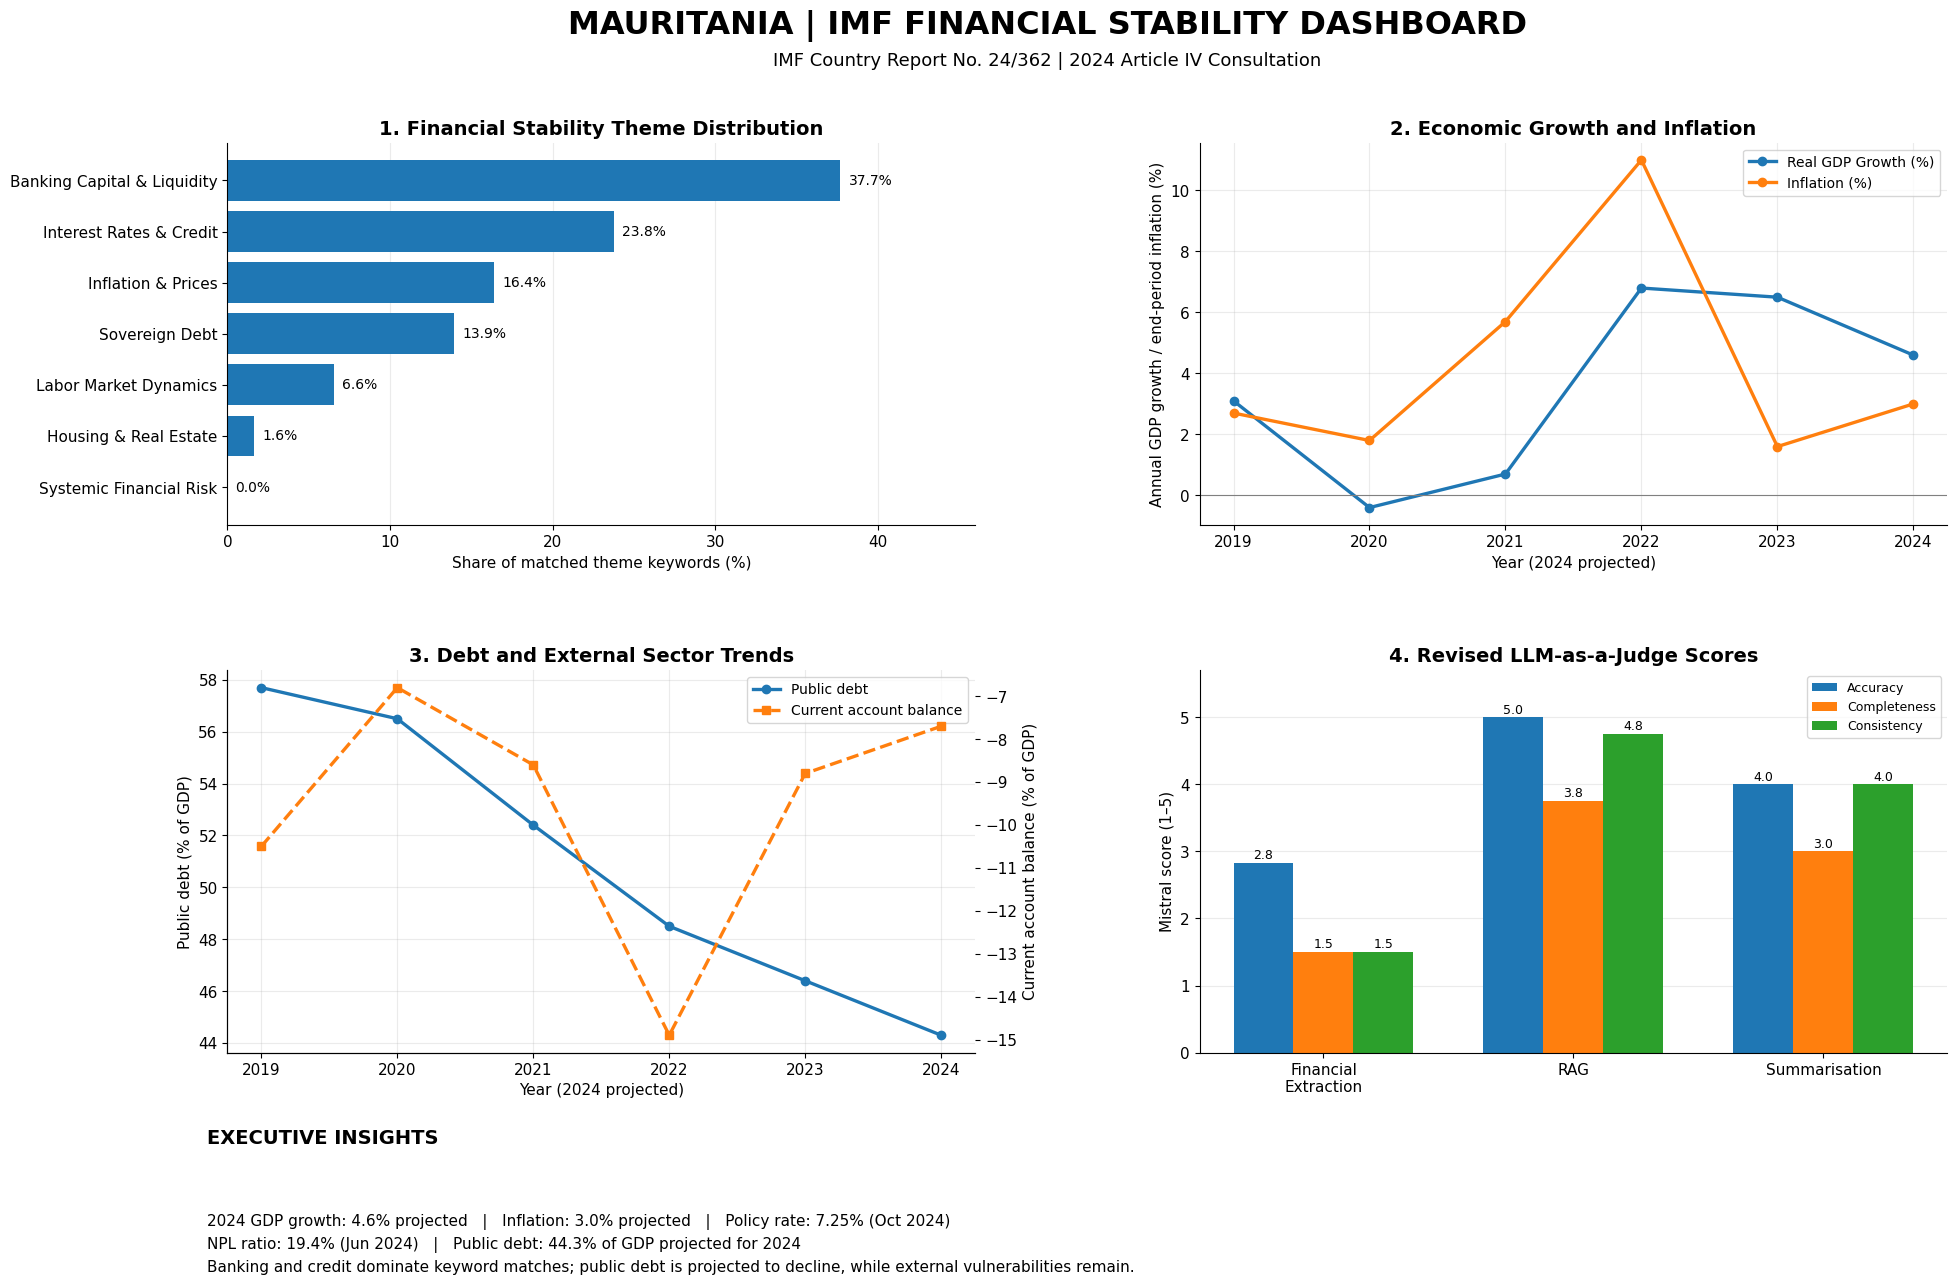

In [15]:
import matplotlib.pyplot as plt

themes_plot = pd.read_csv(output_dir / "financial_themes.csv")
trends = pd.read_csv(output_dir / "economic_trends.csv")
judge = pd.read_csv(output_dir / "judge_comparison.csv")

with open(output_dir / "verified_financial_indicators.json") as f:
    verified = json.load(f)

# Required wide-to-long transformation
trend_wide = trends.pivot(
    index="year", columns="indicator", values="value"
).reset_index()

trend_long = pd.melt(
    trend_wide,
    id_vars="year",
    var_name="indicator",
    value_name="value"
)

judge_plot = judge[judge["evaluation_mode"] == "revised"].set_index("category")

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, axes = plt.subplots(2, 2, figsize=(20, 14))

fig.subplots_adjust(
    left=0.09, right=0.95,
    top=0.87, bottom=0.22,
    hspace=0.38, wspace=0.30
)

fig.suptitle(
    "MAURITANIA | IMF FINANCIAL STABILITY DASHBOARD",
    fontsize=23, fontweight="bold", y=0.965
)

fig.text(
    0.5, 0.925,
    "IMF Country Report No. 24/362 | 2024 Article IV Consultation",
    ha="center", fontsize=13
)

# Panel 1: Financial themes
ax = axes[0, 0]
theme_sorted = themes_plot.sort_values("percentage")

bars = ax.barh(
    theme_sorted["theme"], theme_sorted["percentage"]
)

ax.set_title("1. Financial Stability Theme Distribution", fontweight="bold")
ax.set_xlabel("Share of matched theme keywords (%)")
ax.set_xlim(0, max(theme_sorted["percentage"].max() * 1.22, 1))
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, value in zip(bars, theme_sorted["percentage"]):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height()/2,
        f"{value:.1f}%", va="center", fontsize=10
    )

# Panel 2: GDP and inflation
ax = axes[0, 1]

for name in ["Real GDP Growth (%)", "Inflation (%)"]:
    data = trend_long[trend_long["indicator"] == name]

    ax.plot(
        data["year"], data["value"],
        marker="o", linewidth=2.4, label=name
    )

ax.set_title("2. Economic Growth and Inflation", fontweight="bold")
ax.set_xlabel("Year (2024 projected)")
ax.set_ylabel("Annual GDP growth / end-period inflation (%)")
ax.set_xticks(sorted(trends["year"].unique()))
ax.axhline(0, color="grey", linewidth=0.8)
ax.legend(fontsize=10)
ax.grid(alpha=0.25)

# Panel 3: Debt and current account
ax = axes[1, 0]

debt = trend_long[trend_long["indicator"] == "Public Debt (% GDP)"]
current = trend_long[trend_long["indicator"] == "Current Account (% GDP)"]

line1 = ax.plot(
    debt["year"], debt["value"],
    marker="o", linewidth=2.4, label="Public debt"
)

ax_right = ax.twinx()
line2 = ax_right.plot(
    current["year"], current["value"],
    marker="s", linestyle="--",
    linewidth=2.4, color="tab:orange",
    label="Current account balance"
)

ax.set_title("3. Debt and External Sector Trends", fontweight="bold")
ax.set_xlabel("Year (2024 projected)")
ax.set_ylabel("Public debt (% of GDP)")
ax_right.set_ylabel("Current account balance (% of GDP)")
ax.set_xticks(sorted(trends["year"].unique()))
ax.grid(alpha=0.25)

lines = line1 + line2
ax.legend(lines, [l.get_label() for l in lines], fontsize=10)

# Panel 4: Mistral scores
ax = axes[1, 1]

categories = ["Financial Extraction", "RAG", "Summarisation"]
metrics = ["accuracy", "completeness", "consistency"]
x = np.arange(len(categories))
width = 0.24

for i, metric in enumerate(metrics):
    values = judge_plot.loc[categories, metric].values

    bars = ax.bar(
        x + (i - 1) * width,
        values, width, label=metric.capitalize()
    )

    for bar, value in zip(bars, values):
        if pd.notna(value):
            ax.text(
                bar.get_x() + bar.get_width()/2,
                value + 0.06,
                f"{value:.1f}", ha="center", fontsize=9
            )

ax.set_title("4. Revised LLM-as-a-Judge Scores", fontweight="bold")
ax.set_ylabel("Mistral score (1–5)")
ax.set_ylim(0, 5.7)
ax.set_xticks(x)
ax.set_xticklabels(
    ["Financial\nExtraction", "RAG", "Summarisation"]
)
ax.legend(fontsize=9, loc="upper right")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Executive insights
fig.text(
    0.08, 0.155, "EXECUTIVE INSIGHTS",
    fontsize=14, fontweight="bold"
)

insight_text = (
    f"2024 GDP growth: {verified['gdp_growth_forecast_pct']:.1f}% projected   |   "
    f"Inflation: {verified['headline_inflation_rate_pct']:.1f}% projected   |   "
    f"Policy rate: {verified['central_bank_policy_rate_pct']:.2f}% (Oct 2024)\n"
    f"NPL ratio: {verified['non_performing_loan_ratio']:.1f}% (Jun 2024)   |   "
    "Public debt: 44.3% of GDP projected for 2024\n"
    "Banking and credit dominate keyword matches; public debt is projected to decline, "
    "while external vulnerabilities remain."
)

fig.text(
    0.08, 0.105, insight_text,
    fontsize=11, va="top", linespacing=1.6
)



dashboard_png = output_dir / "mauritania_dashboard.png"
dashboard_pdf = output_dir / "mauritania_dashboard.pdf"

fig.savefig(
    dashboard_png, dpi=320,
    bbox_inches="tight", facecolor="white"
)
fig.savefig(
    dashboard_pdf,
    bbox_inches="tight", facecolor="white"
)

plt.show()
plt.close(fig)